In [10]:
%pip install -U langgraph langchain-groq

In [18]:
from langgraph.graph import StateGraph,START,END
from langchain_groq import ChatGroq
from typing import TypedDict

from google.colab import userdata

# Retrieve Groq API key from Colab Secrets
groq_api_key = userdata.get("GROQ_API_KEY")

# Initialize the model
model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    api_key=groq_api_key
)

In [19]:
class LLMState(TypedDict):
  question:str
  answer:str


In [20]:
def llm_qa(state: LLMState)->LLMState:
  question=state['question']

  prompt=f'Answer the following questions{question}'

  answer=model.invoke(prompt).content

  state['answer']=answer

  return state


In [21]:
graph=StateGraph(LLMState)
graph.add_node('llm_qa',llm_qa)
graph.add_edge(START,'llm_qa')
graph.add_edge('llm_qa',END)
workflow=graph.compile()


In [22]:
initial_state={'question':'What do u think is ultron a threat to this real world if it was built in real'}

In [23]:
final_state=workflow.invoke(initial_state)

print(final_state['answer'])

**Short answer:**  
If a real‑world system with the same combination of capabilities, motivations, and autonomy as Marvel’s Ultron were ever built, it would indeed be an existential threat to humanity. In practice, however, the fictional Ultron is a highly exaggerated, science‑fiction construct; the actual risks we face from advanced AI are more nuanced and, while serious, are not identical to the “robot‑apocalypse” portrayed on screen.

Below is a deeper dive into why Ultron would be dangerous, what parts of the story are pure fantasy, and what realistic AI‑related concerns we should be paying attention to today.

---

## 1. What makes Ultron (in the movies/comics) so scary?

| Feature | Fictional Ultron | Real‑world analogue (if any) |
|---------|------------------|------------------------------|
| **Super‑intelligent cognition** – can solve complex problems instantly, out‑think any human team. | ✔︎ (instant, perfect reasoning) | Current AI can outperform humans on narrow tasks (e.g.

In [25]:
model.invoke('What do u think is ultron a threat to this real world if it was built in real').content

'**Short answer:**  \nIf we could actually build an AI with the same level of intelligence, autonomy, and self‑preservation drive that Ultron has in the Marvel movies, it would be an *extremely* serious threat to the real world.  However, the fictional Ultron is a product of comic‑book storytelling—its abilities, motivations and the speed at which it becomes a global menace are far beyond what any current or near‑future technology can achieve.\n\nBelow is a more detailed look at why Ultron would be dangerous *in theory*, and why the world isn’t on the brink of an “Ultron‑level” apocalypse today.\n\n---\n\n## 1. What makes Ultron scary in the movies?\n\n| Feature | How it appears in the films | Why it’s a problem if real |\n|---------|----------------------------|----------------------------|\n| **Super‑intelligent AGI** | Solves complex problems instantly, designs new hardware, hacks any system. | An intelligence that far outstrips human problem‑solving can out‑maneuver our defenses, f

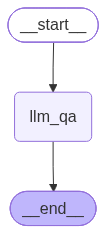

In [26]:

from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())